In [1]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

In [2]:
# Definimos el rango de frecuencias 
nu_min = 2.0 # GHz
nu_max = 4.0 # GHz
spw_tot = 16 # Number of spectral windows
dnu = (nu_max - nu_min)/spw_tot
print(dnu)

0.125


In [3]:
# Defino el valor de los contornos del archivo
#cont = '1.5'
cont = '2.3'

In [4]:
# Defino los errores sistemáticos para cada spw
f = open('rms-per-spw.txt')
# Este archivo contiene el rms en una región de 9x9=81 pixeles

# El archivo para contornos de 1.5mJy tiene 8690 valid pixels
# El archivo para contornos de 2.3mJy tiene 4822 valid pixels
if cont == '1.5':
    factor = 8690/81
elif cont == '2.3':
    factor = 4822/81
    
lines = f.readlines()[1:-3]
f.close()
flux_err_sys = np.empty(len(lines)) 
for i,line in enumerate(lines):
    flux_err_sys[i] = float(line.split('    ')[1])*(8690/81)
    print(f'F_err_sys={flux_err_sys[i]} Jy')

F_err_sys=0.032185185185185185 Jy
F_err_sys=0.032185185185185185 Jy
F_err_sys=0.032185185185185185 Jy
F_err_sys=0.04291358024691358 Jy
F_err_sys=0.02145679012345679 Jy
F_err_sys=0.016092592592592592 Jy
F_err_sys=0.010728395061728395 Jy
F_err_sys=0.016092592592592592 Jy
F_err_sys=0.02145679012345679 Jy
F_err_sys=0.026820987654320987 Jy
F_err_sys=0.02145679012345679 Jy
F_err_sys=0.016092592592592592 Jy


In [5]:
# Leemos los datos del archivo
f = open('flujos-per-spw_' + cont + 'mJy.txt')
lines = f.readlines()[1:]
f.close()

nu = np.empty(len(lines)) 
nu_err = np.empty(len(lines)) 
flux = np.empty(len(lines)) 
flux_err = np.empty(len(lines)) 

for i,line in enumerate(lines):
    spw = int(line.split('=')[1].split(' ')[0])
    nu[i] = nu_min + dnu/2.0 + dnu*spw
    nu_err[i] = dnu/2.0
    flux[i] = float(line.split(' =  ')[1].split(' ')[0]) 
    flux_err[i] = np.sqrt( (0.03*flux[i])**2 + flux_err_sys[i]**2 )
    print(f'spw={spw}, nu={nu[i]} GHz, F={flux[i]} Jy, F_err={flux_err[i]} Jy')

spw=0, nu=2.0625 GHz, F=0.470295 Jy, F_err=0.03514179553931705 Jy
spw=1, nu=2.1875 GHz, F=0.451105 Jy, F_err=0.034914642978658164 Jy
spw=3, nu=2.4375 GHz, F=0.430973 Jy, F_err=0.03468501260574607 Jy
spw=4, nu=2.5625 GHz, F=0.425659 Jy, F_err=0.04477323302444432 Jy
spw=5, nu=2.6875 GHz, F=0.406021 Jy, F_err=0.024673094447170037 Jy
spw=7, nu=2.9375 GHz, F=0.380801 Jy, F_err=0.019735247598955175 Jy
spw=8, nu=3.0625 GHz, F=0.356171 Jy, F_err=0.01514167968613186 Jy
spw=9, nu=3.1875 GHz, F=0.352512 Jy, F_err=0.019256421668647734 Jy
spw=10, nu=3.3125 GHz, F=0.335389 Jy, F_err=0.023698756203458713 Jy
spw=11, nu=3.4375 GHz, F=0.317588 Jy, F_err=0.028462981269059624 Jy
spw=12, nu=3.5625 GHz, F=0.294024 Jy, F_err=0.023199115149515354 Jy
spw=13, nu=3.6875 GHz, F=0.275731 Jy, F_err=0.018094097442980295 Jy


In [6]:
# Agrego los datos viejos
nu2010 = [1.4, 4.86]
nu2010_err = [0.064, 0.064]
if cont == '1.5':
    flux2010 = [0.540, 0.2725] 
elif cont == '2.3':
    flux2010 = [0.390, 0.2344] 

flux2010_err = [flux2010[0]*0.03, flux2010[1]*0.03]

# Armo un vector general (por si lo quiero para el fitteo)
nu2 = np.append(np.append(nu2010[0], nu), nu2010[1])
nu2_err = np.append(np.append(nu2010_err[0], nu_err), nu2010_err[1])
flux2 = np.append(np.append(flux2010[0],flux), flux2010[1])
flux2_err = np.append(np.append([0.03*flux2010[0]], flux_err), [0.03*flux2010[1]])

In [7]:
# Defino la función a ajustar
def po(x,F0,alpha):
    """Power law function"""
    return( F0*np.power(x/3.0,alpha) )

In [8]:
# Defino los valores semilla para el ajuste
seed = np.array([0.5,-0.5])

# Ajusto la función a los datos 
#popt, pcov = curve_fit(po, xdata=nu2, ydata=flux2, p0=seed, sigma=flux2_err, absolute_sigma=True)
popt, pcov = curve_fit(po, xdata=nu, ydata=flux, p0=seed, sigma=flux_err, absolute_sigma=True)
#print(pcov)

perr = np.sqrt(np.diag(pcov))
#print(perr)

for i in range(len(perr)):
    print(str(popt[i])+' +- '+str(perr[i]))

0.35822181102021317 +- 0.006780634232723785
-0.8705384481205142 +- 0.11227117348761873


In [9]:
# prepare confidence level curves
nstd = 3.0 # to draw 1-sigma intervals
popt_up = popt + nstd * perr
popt_dw = popt - nstd * perr

nu_fit = np.linspace(1.4, 4.9, 100)
fit = po(nu_fit, *popt)
fit_up = po(nu_fit, *popt_up)
fit_dw = po(nu_fit, *popt_dw)

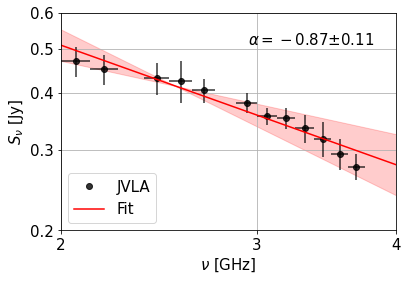

In [16]:
# Grafico datos y ajuste
fig, ax = plt.subplots(1)
plt.rcParams.update({'font.size': 15,
    "font.serif": ["Palatino"]})
plt.grid()
plt.gca().set_xlabel(r'$\nu$ [GHz]')
plt.gca().set_ylabel(r'$S_\nu$ [Jy]')
#plt.errorbar(nu2010, flux2010, yerr=flux2010_err, xerr=nu2010_err, hold=True, ecolor='b', alpha=0.8, fmt='none')
plt.errorbar(nu, flux, yerr=flux_err, xerr=nu_err, hold=True, ecolor='k', alpha=0.8, fmt='none')
#plt.plot(nu2010, flux2010, 'b^', alpha=0.8, label = 'VLA')
plt.plot(nu, flux, 'ko', alpha=0.8, label = 'JVLA')
plt.plot(nu_fit, fit, 'r-', label='Fit')
ax.fill_between(nu_fit, fit_up, fit_dw, alpha=.2, label='', color='r')

plt.title('')

plt.xlim(2,4)
#plt.ylim(0.3,0.9)
plt.ylim(0.2,0.6)

# LINEAR SCALE
#plt.legend(loc='best')
#ax.annotate(r'$\alpha =-$' + str(round(abs(popt[1]),2)) + '$\pm$' + str(round(perr[1],2)),
#            xy=(0, 0), xycoords='axes fraction',
#            xytext=(20, 20), textcoords='offset pixels',
#            horizontalalignment='left',
#            verticalalignment='bottom')

# LOG SCALE
ax.loglog()
ax.set_xticks([2, 3, 4])
#ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
ax.set_yticks([0.2, 0.3, 0.4, 0.5, 0.6])
ax.get_xaxis().set_major_formatter(ScalarFormatter())
ax.get_yaxis().set_major_formatter(ScalarFormatter())
plt.legend(loc='lower left')
ax.annotate(r'$\alpha =-$' + str(round(abs(popt[1]),2)) + '$\pm$' + str(round(perr[1],2)),
            xy=(0.5, 0.75), xycoords='axes fraction',
            xytext=(20, 20), textcoords='offset pixels',
            horizontalalignment='left',
            verticalalignment='bottom')

plt.show()

In [17]:
fig.savefig('BS_' + cont + '.pdf', bbox_inches='tight')

In [12]:
for i in range(len(nu)):
    print(f'{nu[i]} {nu_err[i]} {flux[i]} {flux_err[i]}')

2.0625 0.0625 0.470295 0.03514179553931705
2.1875 0.0625 0.451105 0.034914642978658164
2.4375 0.0625 0.430973 0.03468501260574607
2.5625 0.0625 0.425659 0.04477323302444432
2.6875 0.0625 0.406021 0.024673094447170037
2.9375 0.0625 0.380801 0.019735247598955175
3.0625 0.0625 0.356171 0.01514167968613186
3.1875 0.0625 0.352512 0.019256421668647734
3.3125 0.0625 0.335389 0.023698756203458713
3.4375 0.0625 0.317588 0.028462981269059624
3.5625 0.0625 0.294024 0.023199115149515354
3.6875 0.0625 0.275731 0.018094097442980295


In [13]:
#Quiero E[erg], L[erg]
eV = 1.602176e-12
kpc = 3.0856e21
h = 6.6260755e-27
Jy = 1e-23

d = 1.72*kpc
dil = 4*np.pi*d**2
E, E_err = h*nu*1e9/eV, h*nu_err*1e9/eV
L, L_err = (nu*1e9)*(flux*Jy)*dil, (nu*1e9)*(flux_err*Jy)*dil
for i in range(len(nu)):
    # x_centro	y_centro	x_min		x_max		y_min		y_max
    #print(f'{np.log10(nu[i])} {np.log10(flux[i])} {np.log10(nu[i]-nu_err[i])} {np.log10(nu[i]+nu_err[i])} {np.log10(flux[i]-flux_err[i])} {np.log10(flux[i]+flux_err[i])}')
        print(f'{np.log10(E[i])} {np.log10(L[i])} {np.log10(E[i]-E_err[i])} {np.log10(E[i]+E_err[i])} {np.log10(L[i]-L_err[i])} {np.log10(L[i]+L_err[i])}')

-5.069059884568552 30.535710328289753 -5.082423846126533 -5.056094907404184 30.501982152782315 30.567006821925304
-5.043505780096163 30.543171712045904 -5.056094907404184 -5.031271323679152 30.50818608479507 30.575547893318134
-4.9965092174199395 30.570340696849406 -5.007790227829629 -4.9855138331184765 30.533901541767747 30.60395771421054
-4.974789967726704 30.586671704028358 -4.9855138331184765 -4.964324534048538 30.5384046277679 30.6301069546465
-4.954105368866853 30.586842978980773 -4.964324534048538 -4.944121147960252 30.559615847966615 30.612463399359953
-4.915475966510722 30.597621965023105 -4.924815992764865 -4.906332587070852 30.574510181765433 30.619565709672376
-4.897377744417925 30.58668066255636 -4.906332587070852 -4.88860382011042 30.567813826396584 30.604761886810937
-4.880003648348502 30.59957010856395 -4.88860382011042 -4.87157048081164 30.575173630753238 30.622668700648674
-4.86329795484565 30.594650711125755 -4.87157048081164 -4.855180064623471 30.56282510515396 30.6

In [14]:
print('S_1.4GHz = ' + str(round(po(1.4, *popt),3)) + 'Jy') 

S_1.4GHz = 0.695Jy
